In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
print("¡Entorno de Análisis de Datos configurado con éxito!")

¡Entorno de Análisis de Datos configurado con éxito!


In [4]:
# Configuración de estilo para visualizaciones
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)

# Generación de dataset de prueba realista (simulación de ventas e-commerce)
np.random.seed(42)
n_rows = 500

data = {
    'ID_Transaccion': [f'TRX-{1000 + i}' for i in range(n_rows)],
    'Fecha': pd.date_range(start='2024-01-01', periods=n_rows, freq='h').astype(str),
    'Categoria': np.random.choice(['Electrónica', 'Ropa', 'Hogar', 'Juguetes', None], size=n_rows, p=[0.3, 0.3, 0.2, 0.1, 0.1]),
    'Precio_Unitario': np.random.choice([15.0, 25.5, 120.0, 450.0, 899.9, np.nan], size=n_rows, p=[0.2, 0.3, 0.25, 0.15, 0.05, 0.05]),
    'Cantidad': np.random.randint(-1, 10, size=n_rows), # Incluye valores inconsistentes (-1)
    'Cliente_ID': np.random.randint(5000, 5050, size=n_rows),
    'Metodo_Pago': np.random.choice(['Tarjeta de Crédito', 'PayPal', 'Efectivo', None], size=n_rows, p=[0.5, 0.3, 0.1, 0.1])
}

df_raw = pd.DataFrame(data)

# Guardar copia cruda en la carpeta data
df_raw.to_csv('../data/ventas_raw.csv', index=False)
print("¡Dataset inicial creado y guardado en 'proyecto_1/data/ventas_raw.csv'!")
df_raw.head()


¡Dataset inicial creado y guardado en 'proyecto_1/data/ventas_raw.csv'!


,ID_Transaccion,Fecha,Categoria,Precio_Unitario,Cantidad,Cliente_ID,Metodo_Pago
0,TRX-1000,2024-01-01 00:00:00,Ropa,120.0,6,5038,Tarjeta de Crédito
1,TRX-1001,2024-01-01 01:00:00,NaN,120.0,1,5005,NaN
2,TRX-1002,2024-01-01 02:00:00,Hogar,25.5,6,5016,PayPal
3,TRX-1003,2024-01-01 03:00:00,Ropa,450.0,3,5024,NaN
4,TRX-1004,2024-01-01 04:00:00,Electrónica,120.0,-1,5027,PayPal


In [5]:
# 1. Inspección general de la estructura
print("--- Información General ---")
print(df_raw.info())

print("\n--- Conteo de Valores Nulos ---")
print(df_raw.isnull().sum())

print("\n--- Duplicados ---")
print(f"Filas duplicadas: {df_raw.duplicated().sum()}")

--- Información General ---
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID_Transaccion   500 non-null    str    
 1   Fecha            500 non-null    str    
 2   Categoria        445 non-null    str    
 3   Precio_Unitario  484 non-null    float64
 4   Cantidad         500 non-null    int32  
 5   Cliente_ID       500 non-null    int32  
 6   Metodo_Pago      455 non-null    str    
dtypes: float64(1), int32(2), str(4)
memory usage: 23.6 KB
None

--- Conteo de Valores Nulos ---
ID_Transaccion      0
Fecha               0
Categoria          55
Precio_Unitario    16
Cantidad            0
Cliente_ID          0
Metodo_Pago        45
dtype: int64

--- Duplicados ---
Filas duplicadas: 0


In [6]:
# Hacemos una copia del dataset crudo para realizar la limpieza
df_clean = df_raw.copy()

# 1. Tratamiento de Valores Nulos
# Para categorías, imputamos con 'Sin Información' o la moda
df_clean['Categoria'] = df_clean['Categoria'].fillna('Sin Clasificar')
df_clean['Metodo_Pago'] = df_clean['Metodo_Pago'].fillna('No Especificado')

# Para Precio_Unitario, imputamos con la mediana según la Categoria
df_clean['Precio_Unitario'] = df_clean.groupby('Categoria')['Precio_Unitario'].transform(
    lambda x: x.fillna(x.median())
)

# 2. Corrección de Inconsistencias (Invalidados/Outliers)
# Filtramos cantidades negativas (errores de captura)
df_clean = df_clean[df_clean['Cantidad'] > 0]

# 3. Conversión de Tipos de Datos (Type Casting)
df_clean['Fecha'] = pd.to_datetime(df_clean['Fecha'])
df_clean['Cliente_ID'] = df_clean['Cliente_ID'].astype(str)

# 4. Creación de Nuevas Variables (Feature Engineering)
# Calculamos las ventas totales por transacción
df_clean['Venta_Total'] = df_clean['Precio_Unitario'] * df_clean['Cantidad']

# Verificación final del dataset limpio
print("--- Verificación del Dataset Limpio ---")
print(df_clean.info())
print("\nValores nulos restantes:\n", df_clean.isnull().sum())
print(f"\nTotal de registros válidos para análisis: {len(df_clean)}")
df_clean.head()

--- Verificación del Dataset Limpio ---
<class 'pandas.DataFrame'>
Index: 403 entries, 0 to 498
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   ID_Transaccion   403 non-null    str           
 1   Fecha            403 non-null    datetime64[us]
 2   Categoria        403 non-null    str           
 3   Precio_Unitario  403 non-null    float64       
 4   Cantidad         403 non-null    int32         
 5   Cliente_ID       403 non-null    str           
 6   Metodo_Pago      403 non-null    str           
 7   Venta_Total      403 non-null    float64       
dtypes: datetime64[us](1), float64(2), int32(1), str(4)
memory usage: 26.8 KB
None

Valores nulos restantes:
 ID_Transaccion     0
Fecha              0
Categoria          0
Precio_Unitario    0
Cantidad           0
Cliente_ID         0
Metodo_Pago        0
Venta_Total        0
dtype: int64

Total de registros válidos para análisis: 403


,ID_Transaccion,Fecha,Categoria,Precio_Unitario,Cantidad,Cliente_ID,Metodo_Pago,Venta_Total
0,TRX-1000,2024-01-01 00:00:00,Ropa,120.0,6,5038,Tarjeta de Crédito,720.0
1,TRX-1001,2024-01-01 01:00:00,Sin Clasificar,120.0,1,5005,No Especificado,120.0
2,TRX-1002,2024-01-01 02:00:00,Hogar,25.5,6,5016,PayPal,153.0
3,TRX-1003,2024-01-01 03:00:00,Ropa,450.0,3,5024,No Especificado,1350.0
5,TRX-1005,2024-01-01 05:00:00,Electrónica,15.0,5,5001,Tarjeta de Crédito,75.0


--- Ventas Totales por Categoría ---
        Categoria  Ingresos_Totales  Unidades_Vendidas  Num_Transacciones
3            Ropa          112405.9                633                118
0     Electrónica           92176.1                615                124
1           Hogar           67879.5                384                 78
2        Juguetes           43927.6                222                 43
4  Sin Clasificar           26207.9                200                 40


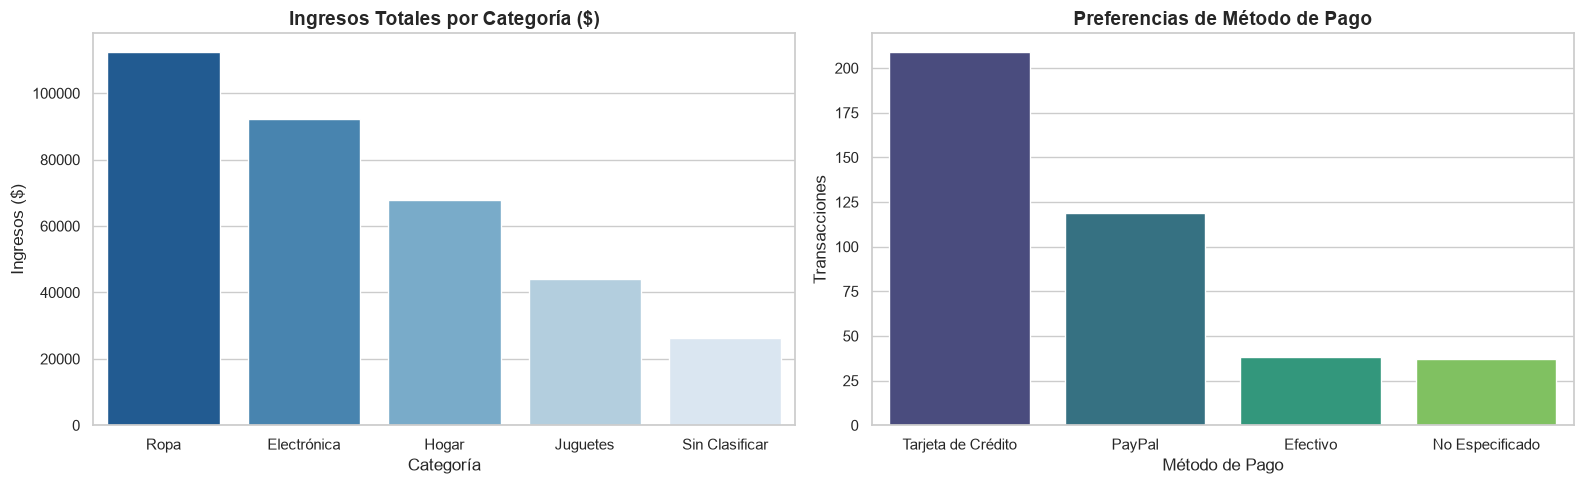


¡Gráfico exportado exitosamente en 'proyecto_1/reports/eda_ventas_categoria_pago.png'!


In [9]:
# 1. Ventas e ingresos por Categoría
ventas_categoria = df_clean.groupby('Categoria').agg(
    Ingresos_Totales=('Venta_Total', 'sum'),
    Unidades_Vendidas=('Cantidad', 'sum'),
    Num_Transacciones=('ID_Transaccion', 'count')
).reset_index().sort_values(by='Ingresos_Totales', ascending=False)

print("--- Ventas Totales por Categoría ---")
print(ventas_categoria)

# 2. Métodos de Pago más utilizados
pago_counts = df_clean['Metodo_Pago'].value_counts().reset_index()
pago_counts.columns = ['Metodo_Pago', 'Cantidad_Transacciones']

# 3. Top 5 Clientes con Mayor Gasto
top_clientes = df_clean.groupby('Cliente_ID')['Venta_Total'].sum().reset_index()
top_clientes = top_clientes.sort_values(by='Venta_Total', ascending=False).head(5)

# --- GENERACIÓN DE GRÁFICOS ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico 1: Ingresos por Categoría
sns.barplot(
    data=ventas_categoria, 
    x='Categoria', 
    y='Ingresos_Totales', 
    hue='Categoria',
    palette='Blues_r', 
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Ingresos Totales por Categoría ($)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Categoría', fontsize=12)
axes[0].set_ylabel('Ingresos ($)', fontsize=12)

# Gráfico 2: Distribución de Métodos de Pago

sns.barplot(
    data=pago_counts, 
    x='Metodo_Pago', 
    y='Cantidad_Transacciones', 
    hue='Metodo_Pago',
    palette='viridis',  # <-- Corregido: 'viridis' en minúsculas
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Preferencias de Método de Pago', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Método de Pago', fontsize=12)
axes[1].set_ylabel('Transacciones', fontsize=12)

plt.tight_layout()
plt.show()

# Guardar figura en la carpeta reports
fig.savefig('../reports/eda_ventas_categoria_pago.png', dpi=300)
print("\n¡Gráfico exportado exitosamente en 'proyecto_1/reports/eda_ventas_categoria_pago.png'!")